# Clase 2 — ¿Qué es el aprendizaje por refuerzo?

**RL a ciegas** · curso de aprendizaje por refuerzo (*reinforcement learning*, RL) · vía profunda

Basado en Stanford CS234 (Brunskill), clase 1; Stanford CS224R, clase 1; y Sutton & Barto, cap. 1 y 3.

En esta clase vamos a ver:

1. **Dónde aparece RL hoy y qué tiene de distinto**: el problema sin respuesta correcta.
2. **El ciclo agente–entorno**: alguien decide, el mundo responde.
3. **La política**: la regla que elige. Un agente al azar contra uno con flechas.
4. **Qué se maximiza**: la suma de recompensas, con un agente aleatorio en la cueva a oscuras.
5. **Historia vs. estado** y el **supuesto de Markov**: ¿qué tiene que recordar el agente?
6. **Aula invertida: el tutor de IA como proceso de decisión**. Ustedes diseñan el problema… y descubren una trampa.

> Cómo usar este notebook: ejecutar las celdas en orden (Colab: *Entorno de ejecución → Ejecutar todas*). Tarda menos de un minuto.

## Preparación

La primera celda escribe el archivo `cave_env.py` con **la cueva** que usamos en todo el curso. Así el notebook funciona solo, también en Colab. No hace falta leerla.

In [1]:
%%writefile cave_env.py
"""
cave_env.py — La cueva a ciegas (entorno del mini curso de RL).

Una grilla discreta. El agente no ve el mapa: solo se entera de que hay una
pared cuando choca contra ella (en el juego, la pared se pinta de gris claro).
La salida es el cuadrado verde 'G'.

API mínima (estilo Gymnasium, sin dependencias):
    env = CaveEnv()
    s = env.reset()                 # estado = índice entero de la casilla
    s, r, done, info = env.step(a)  # a en {0:arriba, 1:derecha, 2:abajo, 3:izquierda}
    info["bump"]                    # True si chocó con una pared

Para la clase 4 (planificar con mapa): env.P[s, a, s'] y env.R[s, a].
"""
import numpy as np

CAVE_MAP = [
    "##############",
    "#S...#.......#",
    "#.##.#.####..#",
    "#.#..#....#..#",
    "#.#.####..#.##",
    "#.#......##..#",
    "#.####.#..#..#",
    "#......#.##..#",
    "###.####....G#",
    "##############",
]

ACTIONS = {0: (-1, 0), 1: (0, 1), 2: (1, 0), 3: (0, -1)}
ACTION_NAMES = ["↑", "→", "↓", "←"]


class CaveEnv:
    def __init__(self, cave_map=CAVE_MAP, goal_reward=1.0, step_reward=0.0,
                 bump_reward=0.0, slip=0.0, max_steps=200, seed=None):
        self.grid = np.array([list(row) for row in cave_map])
        self.H, self.W = self.grid.shape
        self.goal_reward, self.step_reward, self.bump_reward = goal_reward, step_reward, bump_reward
        self.slip, self.max_steps = slip, max_steps
        self.rng = np.random.default_rng(seed)
        self.free = [(r, c) for r in range(self.H) for c in range(self.W) if self.grid[r, c] != "#"]
        self.pos2s = {p: i for i, p in enumerate(self.free)}
        self.nS, self.nA = len(self.free), 4
        self.start = self.pos2s[tuple(np.argwhere(self.grid == "S")[0])]
        self.goal = self.pos2s[tuple(np.argwhere(self.grid == "G")[0])]
        self._build_model()
        self.reset()

    # ---------- dinámica ----------
    def _move(self, s, a):
        r, c = self.free[s]
        dr, dc = ACTIONS[a]
        nr, nc = r + dr, c + dc
        if self.grid[nr, nc] == "#":
            return s, True
        return self.pos2s[(nr, nc)], False

    def _reward(self, s_next, bump):
        if s_next == self.goal:
            return self.goal_reward
        return self.step_reward + (self.bump_reward if bump else 0.0)

    def _build_model(self):
        """Modelo del mundo: P[s,a,s'] y R[s,a] (recompensa esperada). La meta es absorbente."""
        nS, nA = self.nS, self.nA
        self.P = np.zeros((nS, nA, nS))
        self.R = np.zeros((nS, nA))
        for s in range(nS):
            for a in range(nA):
                if s == self.goal:
                    self.P[s, a, s] = 1.0
                    continue
                # con prob 1-slip va adonde quiere; con slip, a una dirección perpendicular
                outcomes = [(a, 1 - self.slip)]
                if self.slip > 0:
                    outcomes += [((a + 1) % 4, self.slip / 2), ((a + 3) % 4, self.slip / 2)]
                for aa, p in outcomes:
                    s2, bump = self._move(s, aa)
                    self.P[s, a, s2] += p
                    self.R[s, a] += p * self._reward(s2, bump)

    def reset(self):
        self.s, self.t = self.start, 0
        self.touched = set()          # paredes descubiertas (para dibujar)
        return self.s

    def step(self, a):
        if self.slip > 0 and self.rng.random() < self.slip:
            a = (a + self.rng.choice([1, 3])) % 4
        s2, bump = self._move(self.s, a)
        if bump:
            r, c = self.free[self.s]
            dr, dc = ACTIONS[a]
            self.touched.add((r + dr, c + dc))
        rew = self._reward(s2, bump)
        self.s, self.t = s2, self.t + 1
        done = s2 == self.goal or self.t >= self.max_steps
        return s2, rew, done, {"bump": bump, "reached_goal": s2 == self.goal}

    # ---------- observaciones para Deep RL ----------
    def observe(self, s=None, kind="onehot"):
        s = self.s if s is None else s
        if kind == "onehot":
            x = np.zeros(self.nS, dtype=np.float32); x[s] = 1; return x
        r, c = self.free[s]
        if kind == "coords":
            return np.array([r / (self.H - 1), c / (self.W - 1)], dtype=np.float32)
        if kind == "coords+touch":   # posición + 4 "bigotes" que sienten paredes vecinas
            walls = [float(self.grid[r + dr, c + dc] == "#") for dr, dc in ACTIONS.values()]
            return np.array([r / (self.H - 1), c / (self.W - 1)] + walls, dtype=np.float32)
        raise ValueError(kind)

    # ---------- dibujo ----------
    def to_grid(self, values):
        g = np.full((self.H, self.W), np.nan)
        for s, (r, c) in enumerate(self.free):
            g[r, c] = values[s]
        return g

    def plot(self, values=None, policy=None, ax=None, title=None, cmap="magma",
             show_walls=True, path=None):
        import matplotlib.pyplot as plt
        if ax is None:
            _, ax = plt.subplots(figsize=(self.W * 0.5, self.H * 0.5))
        bg = np.zeros((self.H, self.W, 3))
        if show_walls:
            bg[self.grid == "#"] = 0.8      # gris claro: la pared "tocada"
        ax.imshow(bg)
        if values is not None:
            im = ax.imshow(self.to_grid(values), cmap=cmap, alpha=0.9)
            plt.colorbar(im, ax=ax, fraction=0.03)
        gr, gc = self.free[self.goal]
        ax.add_patch(plt.Rectangle((gc - .5, gr - .5), 1, 1, color="#2ecc71"))
        sr, sc = self.free[self.start]
        ax.text(sc, sr, "S", ha="center", va="center", color="w", fontsize=11, weight="bold")
        if policy is not None:
            for s, (r, c) in enumerate(self.free):
                if s != self.goal:
                    ax.text(c, r, ACTION_NAMES[int(policy[s])], ha="center", va="center",
                            color="cyan", fontsize=11)
        if path is not None:
            rc = np.array([self.free[s] for s in path])
            ax.plot(rc[:, 1], rc[:, 0], "-", color="#3498db", lw=2, alpha=.8)
        ax.set_xticks([]); ax.set_yticks([])
        if title: ax.set_title(title)
        return ax

Overwriting cave_env.py


Ahora importamos la cueva y las bibliotecas de siempre (`numpy` para números, `matplotlib` para gráficos). Fijamos una semilla para que todos veamos los mismos resultados y le ponemos nombre a las cuatro acciones.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from cave_env import CaveEnv, ACTION_NAMES

SEMILLA = 0
np.random.seed(SEMILLA)
ARRIBA, DERECHA, ABAJO, IZQUIERDA = 0, 1, 2, 3
print("Acciones:", ACTION_NAMES)

Acciones: ['↑', '→', '↓', '←']


La celda siguiente define **herramientas** (funciones de dibujo y simulación). Está plegada: no hace falta leerla, solo ejecutarla. Las celdas de la clase llaman a estas funciones con una línea.

In [3]:
# @title Herramientas (no hace falta leer esto)
# Herramientas: no hace falta leer esto
import matplotlib.patches as mpatches

COLORES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
plt.rcParams.update({
    "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.8,
    "axes.edgecolor": "#888888", "axes.titlesize": 12, "font.size": 10.5,
    "lines.linewidth": 2, "axes.axisbelow": True,
})


# ---------- flechas calculadas con el mapa (la clase 4 explica cómo) ----------
def flechas_con_mapa(env, gamma=0.95, tol=1e-10):
    """Iteración de valor sobre env.P y env.R. Devuelve una flecha (acción) por casilla."""
    V = np.zeros(env.nS)
    while True:
        Q = env.R + gamma * env.P @ V
        V_nuevo = Q.max(axis=1)
        if np.max(np.abs(V_nuevo - V)) < tol:
            break
        V = V_nuevo
    return Q.argmax(axis=1)


# ---------- 1. supervisado contra RL ----------
def supervisado_vs_rl(env, politica):
    fig, axs = plt.subplots(1, 2, figsize=(13, 4.6))
    env.plot(policy=politica, ax=axs[0],
             title="Aprendizaje supervisado: la respuesta correcta en cada casilla")
    env.plot(show_walls=False, ax=axs[1], title="RL: a oscuras, y solo un número al llegar")
    gr, gc = env.free[env.goal]
    axs[1].text(gc, gr, "+1", ha="center", va="center", color="k", fontsize=11, weight="bold")
    plt.tight_layout(); plt.show()


# ---------- 2. ciclo agente-entorno ----------
def dibujar_ciclo():
    fig, ax = plt.subplots(figsize=(8, 3.6))
    ax.set_xlim(0, 10); ax.set_ylim(0, 5); ax.axis("off")
    for x, nombre, sub, col in [(0.6, "Agente", "decide", COLORES[0]), (6.4, "Mundo", "responde", COLORES[2])]:
        ax.add_patch(mpatches.FancyBboxPatch((x, 1.5), 3, 2, boxstyle="round,pad=0.1",
                                             fc=col, ec="none", alpha=0.18))
        ax.text(x + 1.5, 2.75, nombre, ha="center", va="center", fontsize=16, weight="bold", color="#222")
        ax.text(x + 1.5, 2.15, sub, ha="center", va="center", fontsize=11, color="#555")
    flecha = dict(arrowstyle="-|>", lw=2, color="#333", mutation_scale=18)
    ax.annotate("", xy=(6.4, 3.9), xytext=(3.6, 3.9), arrowprops=dict(**flecha, connectionstyle="arc3,rad=-0.25"))
    ax.text(5, 4.65, r"acción $a_t$", ha="center", fontsize=13)
    ax.annotate("", xy=(3.6, 1.1), xytext=(6.4, 1.1), arrowprops=dict(**flecha, connectionstyle="arc3,rad=-0.25"))
    ax.text(5, 0.05, r"observación $o_t$,  recompensa $r_t$", ha="center", fontsize=13)
    ax.set_title("El ciclo agente–entorno (se repite en t = 1, 2, 3, ...)")
    plt.show()


def ciclo_en_la_cueva(env, acciones):
    """Juega las acciones dadas e imprime cada vuelta del ciclo."""
    s = env.reset()
    print(f"{'t':>2}  {'acción':>6}  {'observación (casilla fila, col)':>32}  {'¿chocó?':>8}  {'recompensa':>10}")
    for t, a in enumerate(acciones, start=1):
        s, r, done, info = env.step(a)
        print(f"{t:>2}  {ACTION_NAMES[a]:>6}  {str(env.free[s]):>32}  {'sí' if info['bump'] else 'no':>8}  {r:>10}")
        if done:
            break


# ---------- 3 y 4. episodios ----------
def correr_episodio(env, rng, politica=None):
    """Juega un episodio. politica: None (al azar) o un arreglo con una acción por casilla.
    Devuelve (camino de estados, retorno, ¿llegó?)."""
    s = env.reset(); camino = [s]; G = 0.0; done = False; info = {"reached_goal": False}
    while not done:
        a = rng.integers(env.nA) if politica is None else int(politica[s])
        s, r, done, info = env.step(a)
        camino.append(s); G += r
    return camino, G, info["reached_goal"]


def recompensas_de_un_episodio(env, rng, politica=None):
    s = env.reset(); rs = []; done = False
    while not done:
        a = rng.integers(env.nA) if politica is None else int(politica[s])
        s, r, done, info = env.step(a); rs.append(r)
    return np.array(rs), info["reached_goal"]


def dos_politicas(politica, limite=200, seed=0):
    env = CaveEnv(max_steps=limite)
    cam_azar, _, ok_azar = correr_episodio(env, np.random.default_rng(seed))
    cam_flechas, _, ok_flechas = correr_episodio(env, np.random.default_rng(seed), politica)
    fig, axs = plt.subplots(1, 2, figsize=(13, 4.6))
    env.plot(path=cam_azar, ax=axs[0],
             title=f"Al azar: {len(cam_azar) - 1} pasos, ¿salió? {'sí' if ok_azar else 'no'}")
    env.plot(policy=politica, path=cam_flechas, ax=axs[1],
             title=f"Flechas fijas: {len(cam_flechas) - 1} pasos, ¿salió? {'sí' if ok_flechas else 'no'}")
    plt.tight_layout(); plt.show()
    return len(cam_flechas) - 1


def pasos_hasta_salir(n_episodios=300, seed=0, politica=None):
    """Sin límite de pasos: ¿cuántos pasos tarda en encontrar la salida?"""
    env = CaveEnv(max_steps=10**6); rng = np.random.default_rng(seed); pasos = []
    for _ in range(n_episodios):
        camino, _, _ = correr_episodio(env, rng, politica)
        pasos.append(len(camino) - 1)
    return np.array(pasos)


def comparar_dos_politicas(pasos_azar, pasos_flechas, limite=200):
    nombres = ["al azar", "flechas fijas"]
    exito = [np.mean(p <= limite) * 100 for p in (pasos_azar, pasos_flechas)]
    medianas = [np.median(p) for p in (pasos_azar, pasos_flechas)]
    fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
    for ax, vals, tit, fmt in [(axs[0], exito, f"% de episodios que salen en {limite} pasos", "%.1f%%"),
                               (axs[1], medianas, "Mediana de pasos hasta salir (sin límite)", "%.0f")]:
        bars = ax.bar(nombres, vals, color=[COLORES[1], COLORES[0]], width=0.55)
        ax.bar_label(bars, fmt=fmt, padding=3)
        ax.set_title(tit); ax.grid(axis="x", visible=False); ax.set_ylim(0, max(vals) * 1.2)
    plt.tight_layout(); plt.show()
    print(f"{'política':15s} {'éxito en ' + str(limite):>12s} {'mediana de pasos':>17s}")
    for n, e, m in zip(nombres, exito, medianas):
        print(f"{n:15s} {e:11.1f}% {m:17.0f}")


def pintar_paredes_tocadas(env, camino, ax=None, title=None):
    """Como en el juego: fondo negro y solo las paredes tocadas, en gris claro."""
    ax = env.plot(show_walls=False, path=camino, ax=ax, title=title)
    for (r, c) in env.touched:
        ax.add_patch(plt.Rectangle((c - .5, r - .5), 1, 1, color="0.8"))
    return ax


def tres_vistas(env, camino):
    fig, axs = plt.subplots(1, 3, figsize=(17, 4.6))
    env.plot(show_walls=False, path=camino, ax=axs[0], title="1. Lo que ve el agente: nada")
    pintar_paredes_tocadas(env, camino, ax=axs[1],
                           title=f"2. Lo que descubrió: {len(env.touched)} paredes tocadas")
    env.plot(path=camino, ax=axs[2], title="3. El mapa real (solo lo vemos nosotros)")
    plt.tight_layout(); plt.show()


def dibujar_recompensas(rs_azar, rs_flechas):
    fig, axs = plt.subplots(2, 1, figsize=(11, 4.6))
    for ax, rs, nombre, col in [(axs[0], rs_azar, "al azar", COLORES[1]), (axs[1], rs_flechas, "flechas fijas", COLORES[0])]:
        t = np.arange(1, len(rs) + 1)
        ax.vlines(t, 0, rs, color=col, lw=2)
        ax.plot(t, rs, "o", ms=2.5, color=col)
        ax.set_xlim(0, len(rs_azar) + 1); ax.set_ylim(-0.1, 1.3); ax.set_yticks([0, 1])
        ax.set_ylabel("$r_t$")
        ax.set_title(f"Política {nombre}: {int(np.sum(rs == 0))} recompensas 0 y un +1 en el paso {len(rs)}",
                     fontsize=11)
    axs[1].set_xlabel("paso t")
    plt.tight_layout(); plt.show()


def histograma_pasos(pasos, limite=200):
    exito = np.mean(pasos <= limite) * 100
    fig, ax = plt.subplots(figsize=(9, 3.8))
    ax.hist(pasos, bins=40, color=COLORES[0], edgecolor="white", linewidth=1)
    ax.axvline(limite, color="#333", ls="--", lw=1.5)
    ax.axvline(np.median(pasos), color=COLORES[1], lw=1.5)
    ax.text(0.98, 0.95, f"línea punteada: límite del juego ({limite} pasos)\n"
            f"solo {exito:.1f}% de los episodios sale antes\n\n"
            f"línea naranja: mediana = {np.median(pasos):.0f} pasos",
            transform=ax.transAxes, ha="right", va="top", fontsize=11)
    ax.set_xlabel("pasos hasta llegar a la salida"); ax.set_ylabel("episodios")
    ax.set_title(f"Agente aleatorio: {len(pasos)} episodios")
    plt.show()
    return exito


# ---------- 5. historia vs estado ----------
def camino_de_acciones(env, acciones):
    s = env.reset(); camino = [s]
    for a in acciones:
        s, _, _, _ = env.step(a); camino.append(s)
    return camino


def dos_historias(env, acciones_A, acciones_B):
    camA = camino_de_acciones(env, acciones_A)
    camB = camino_de_acciones(env, acciones_B)
    fig, axs = plt.subplots(1, 2, figsize=(12, 4.6))
    for ax, cam, nombre in [(axs[0], camA, "A"), (axs[1], camB, "B")]:
        env.plot(path=cam, ax=ax, title=f"Historia {nombre}: {len(cam) - 1} pasos")
        r, c = env.free[cam[-1]]
        ax.plot(c, r, "o", ms=16, mfc="none", mec=COLORES[1], mew=3)
    plt.suptitle("Dos historias distintas, la misma casilla (círculo naranja)", y=1.02)
    plt.tight_layout(); plt.show()
    return camA[-1], camB[-1]


def firma_paredes(env, s):
    """Lo que sentiría un agente que SOLO percibe paredes vecinas: 4 bigotes (↑ → ↓ ←)."""
    return tuple(env.observe(s, kind="coords+touch")[2:].astype(int))


# ---------- 6. tutor de IA ----------
HAB_INICIAL = {"suma": 0.10, "resta": 0.05}   # prob. de acertar al principio
VELOCIDAD = {"suma": 0.12, "resta": 0.04}     # cuánto aprende por cada problema practicado


def recompensa_original(acierto, tipo, hab_antes, hab_despues):
    return 1.0 if acierto else -1.0


POLITICAS_TUTOR = {
    "solo sumas":        lambda t, rng: "suma",
    "alternar":          lambda t, rng: "suma" if t % 2 == 0 else "resta",
    "mayormente restas": lambda t, rng: "resta" if rng.random() < 0.8 else "suma",
}


def simular_tutor(politica, recompensa=recompensa_original, n_problemas=60, n_alumnos=300, seed=0):
    """Simula muchos alumnos. Devuelve recompensa acumulada media (curva) y habilidades finales medias."""
    rng = np.random.default_rng(seed)
    curvas = np.zeros((n_alumnos, n_problemas)); finales = []
    for i in range(n_alumnos):
        hab = dict(HAB_INICIAL); G = 0.0
        for t in range(n_problemas):
            tipo = politica(t, rng)
            acierto = rng.random() < hab[tipo]
            antes = dict(hab)
            hab[tipo] += VELOCIDAD[tipo] * (1 - hab[tipo])      # practicar mejora (con rendimientos decrecientes)
            G += recompensa(acierto, tipo, antes, dict(hab))
            curvas[i, t] = G
        finales.append([hab["suma"], hab["resta"]])
    return curvas.mean(0), np.mean(finales, axis=0)


def comparar_politicas_tutor(recompensa=recompensa_original, titulo_r="recompensa +1/−1"):
    res = {n: simular_tutor(p, recompensa) for n, p in POLITICAS_TUTOR.items()}
    fig, axs = plt.subplots(1, 3, figsize=(17, 4.3))
    for k, (n, (curva, fin)) in enumerate(res.items()):
        axs[0].plot(np.arange(1, len(curva) + 1), curva, color=COLORES[k], label=n)
        axs[0].text(len(curva) + 1, curva[-1], n, va="center", fontsize=10, color="#333")
    axs[0].set_xlim(0, len(curva) * 1.35)
    axs[0].set_xlabel("problema número"); axs[0].set_ylabel("recompensa acumulada")
    axs[0].set_title(f"Lo que ve el tutor: {titulo_r}"); axs[0].legend(loc="upper left", frameon=False)
    nombres = list(res)
    R = [res[n][0][-1] for n in nombres]
    A = [res[n][1].mean() * 100 for n in nombres]
    for ax, vals, tit, lab in [(axs[1], R, "Recompensa total (lo que optimiza el tutor)", "recompensa"),
                               (axs[2], A, "Lo aprendido al final (lo que queremos)", "% promedio de acierto en suma y resta")]:
        bars = ax.bar(nombres, vals, color=[COLORES[k] for k in range(len(nombres))], width=0.6)
        ax.bar_label(bars, fmt="%.0f", padding=3)
        ax.set_title(tit); ax.set_ylabel(lab); ax.grid(axis="x", visible=False)
        ax.set_ylim(min(0, min(vals) * 1.2), max(vals) * 1.2)
    plt.tight_layout(); plt.show()
    print(f"{'política':20s} {'recompensa':>11s} {'suma final':>11s} {'resta final':>12s}")
    for n in nombres:
        print(f"{n:20s} {res[n][0][-1]:11.1f} {res[n][1][0]*100:10.0f}% {res[n][1][1]*100:11.0f}%")

## 1. Dónde aparece RL hoy y qué tiene de distinto

Dos ejemplos conocidos, con su fuente:

- **Juegos.** AlphaGo aprendió a jugar al Go combinando redes neuronales, búsqueda en el árbol de jugadas y aprendizaje por refuerzo jugando contra sí mismo; le ganó 5 a 0 al campeón europeo Fan Hui (Silver et al., 2016).
- **Asistentes conversacionales.** Los modelos de lenguaje se ajustan con *RL a partir de retroalimentación humana* (*RL from human feedback*, RLHF): personas comparan respuestas, con esas comparaciones se entrena un modelo de recompensa y el modelo de lenguaje se optimiza con RL para obtener más recompensa. En el trabajo de InstructGPT, las personas prefirieron las respuestas de un modelo así ajustado de 1300 millones de parámetros a las de GPT-3, más de cien veces más grande (Ouyang et al., 2022).

¿Qué tienen en común estos problemas con salir de una cueva a oscuras? Que **nadie da la respuesta correcta**.

### Paso 1 — Lo que recibe el que aprende

A la izquierda, lo que tendría un problema de **aprendizaje supervisado** (*supervised learning*): para cada casilla, alguien nos dice la flecha correcta (como una etiqueta en un conjunto de datos). A la derecha, lo que tiene el agente de RL: la cueva a oscuras y un **+1** cuando llega a la salida. Nada más.

(Las flechas de la izquierda las calculamos nosotros mirando el mapa; en la clase 4 vamos a ver cómo.)

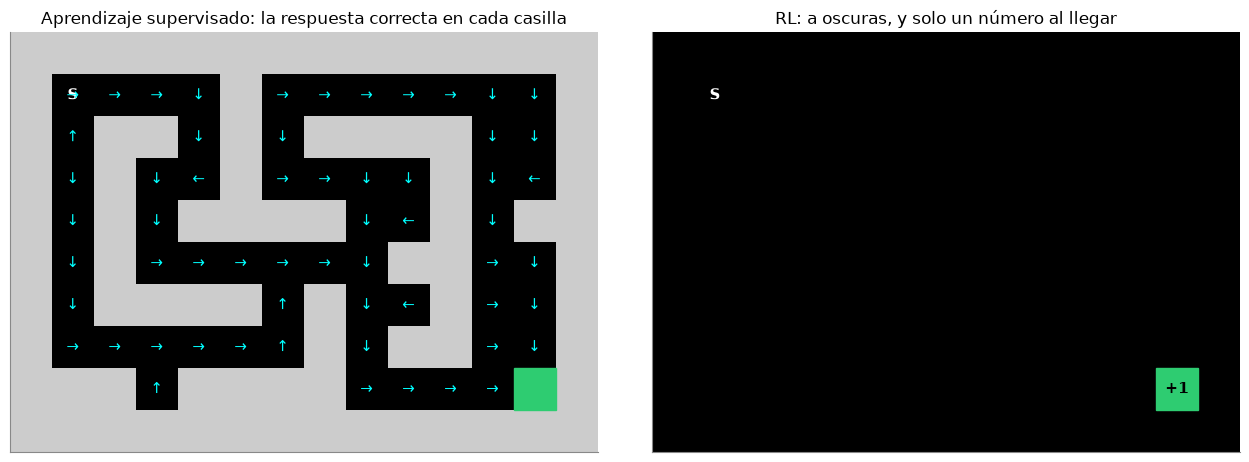

In [4]:
env = CaveEnv(max_steps=200)
politica_flechas = flechas_con_mapa(env)
supervisado_vs_rl(env, politica_flechas)

En el aprendizaje supervisado, cada error se corrige en el momento: "acá era ↓, no →". En RL el agente solo recibe un número, a veces mucho después, y tiene que deducir por su cuenta qué hizo bien. Lo que hace difícil a RL se resume en cuatro ingredientes (CS234, clase 1):

| Ingrediente | ¿Qué significa en la cueva? |
|---|---|
| **Optimización** (*optimization*) | queremos salir, y rápido |
| **Consecuencias demoradas** (*delayed consequences*) | el +1 llega recién al final: un paso a la izquierda ahora puede ser lo que permite salir 30 pasos después |
| **Exploración** (*exploration*) | no vemos el mapa: solo sabemos qué hay detrás de una pared si chocamos con ella |
| **Generalización** (*generalization*) | ¿lo aprendido en esta cueva sirve en otra? |

En el Go y en los asistentes pasa lo mismo: nadie sabe cuál era "la jugada correcta" o "la respuesta correcta" en cada paso; solo se sabe, al final, si se ganó o qué respuesta prefirió una persona.

**Tres parientes de RL** que vamos a cruzar en el curso: el **RL basado en modelo** (*model-based RL*), donde el agente conoce o aprende cómo funciona el mundo —en la cueva, el mapa $P(s' \mid s, a)$— y planifica con él (clase 4); el **aprendizaje por imitación** (*imitation learning*), donde en vez de recompensa hay demostraciones de un experto (clase 10); y **RLHF**, donde la recompensa no se escribe a mano sino que se aprende de comparaciones hechas por personas (clase 12).

## 2. El ciclo agente–entorno

Primero la figura, después las palabras.

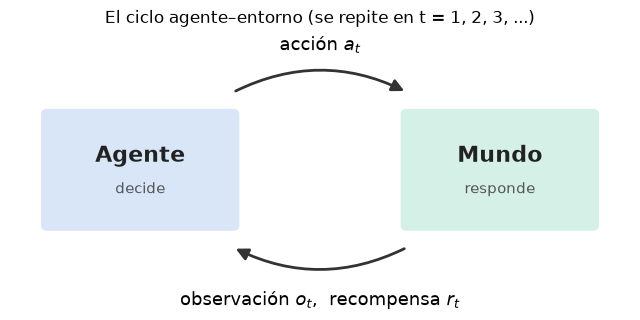

In [5]:
dibujar_ciclo()

En cada instante $t$:

- el **agente** (*agent*) elige una **acción** $a_t$;
- el **mundo** o **entorno** (*environment*) cambia y le devuelve una **observación** $o_t$ y una **recompensa** $r_t$ (un número: bueno si es alto).

### Paso 1 — El ciclo en la cueva, vuelta por vuelta

En la cueva: el agente es quien camina; el entorno es la cueva; las acciones son ↑ → ↓ ←; la observación es la casilla donde quedó (y si chocó con una pared); la recompensa es **+1 al llegar a la salida y 0 en cualquier otro paso**. Juguemos seis acciones elegidas a mano y miremos cada vuelta del ciclo.

In [6]:
ciclo_en_la_cueva(env, [DERECHA, DERECHA, DERECHA, DERECHA, ABAJO, ABAJO])

 t  acción   observación (casilla fila, col)   ¿chocó?  recompensa
 1       →                            (1, 2)        no         0.0
 2       →                            (1, 3)        no         0.0
 3       →                            (1, 4)        no         0.0
 4       →                            (1, 4)        sí         0.0
 5       ↓                            (2, 4)        no         0.0
 6       ↓                            (3, 4)        no         0.0


La cuarta acción (→) choca: la casilla no cambia y el agente se entera de que ahí hay una pared. En las seis vueltas la recompensa fue 0: nada le dice si va bien o mal.

## 3. La política: la regla que elige

¿Quién elige la acción? Una **política** (*policy*): una regla que, para cada estado, dice qué hacer.

$$a = \pi(s)$$

La política es **lo que el agente aprende**. Vamos a comparar dos políticas en la misma cueva:

- **al azar**: en cada paso tira un dado de cuatro caras;
- **flechas fijas**: en cada casilla hay una flecha y el agente siempre la sigue (son las flechas de la sección 1).

### Paso 1 — Dos políticas, un episodio cada una (límite: 200 pasos)

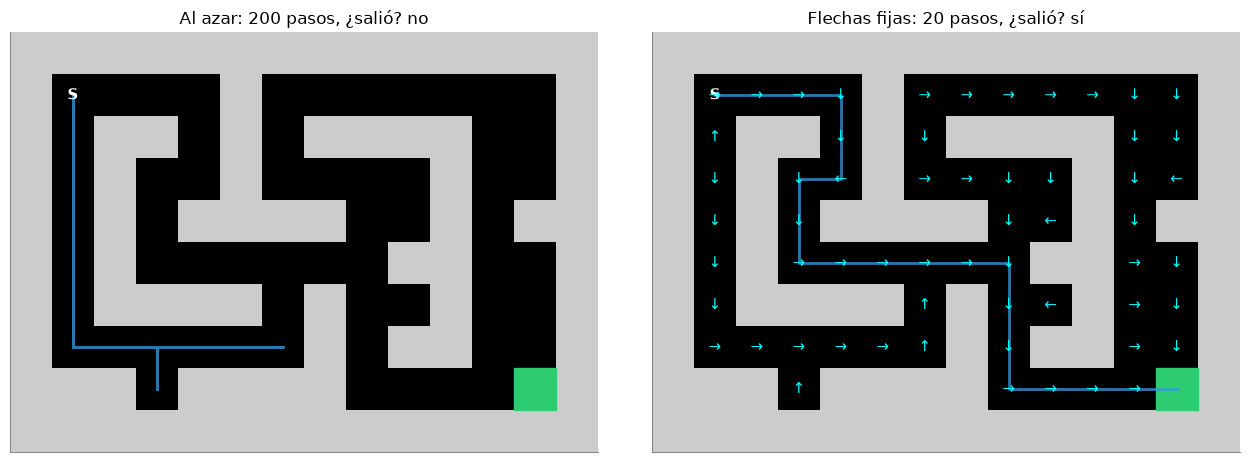

Con las flechas, el agente sale en 20 pasos.


In [7]:
pasos_flechas = dos_politicas(politica_flechas, limite=200, seed=SEMILLA)
print(f"Con las flechas, el agente sale en {pasos_flechas} pasos.")

El agente al azar va y vuelve por los mismos pasillos y no sale; el de las flechas va derecho a la salida. Los dos viven en la misma cueva, con las mismas acciones y la misma recompensa: **lo único que cambia es la política**.

### Paso 2 — Muchos episodios: ¿cuánto mejor es una buena política?

Un solo episodio puede ser suerte. Jugamos **300 episodios** con cada política, sin límite de pasos, y medimos cuántos pasos tarda cada una en salir. Después contamos qué porcentaje sale dentro de los 200 pasos del juego.

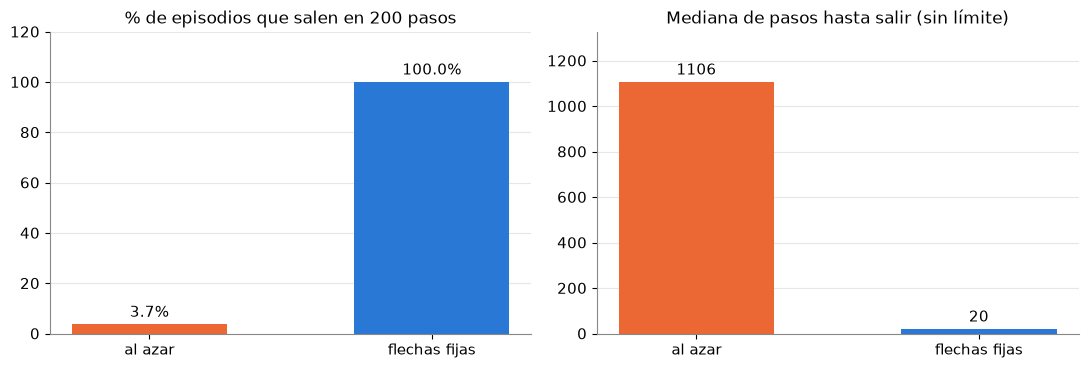

política        éxito en 200  mediana de pasos
al azar                 3.7%              1106
flechas fijas         100.0%                20


In [8]:
pasos_azar = pasos_hasta_salir(n_episodios=300, seed=SEMILLA)
pasos_flechas_300 = pasos_hasta_salir(n_episodios=300, seed=SEMILLA, politica=politica_flechas)
comparar_dos_politicas(pasos_azar, pasos_flechas_300, limite=200)

Las flechas salen siempre y por el camino más corto (la cueva no tiene azar: la misma flecha da siempre el mismo paso). El azar, en cambio, casi nunca sale en 200 pasos y su mediana está muy por encima del límite. Aprender, en RL, es ir de la política de la izquierda a la de la derecha **usando solo la recompensa**.

### ✍️ Ejercicio — Rompan una flecha

Una política es una regla fija: si una flecha está mal, el agente repite el error para siempre. Cambien la flecha de **una** casilla y miren qué pasa. Por ejemplo, la casilla `(1, 2)` (a la derecha de `S`) apuntando a la izquierda (`IZQUIERDA`). Prueben también otras casillas del camino.

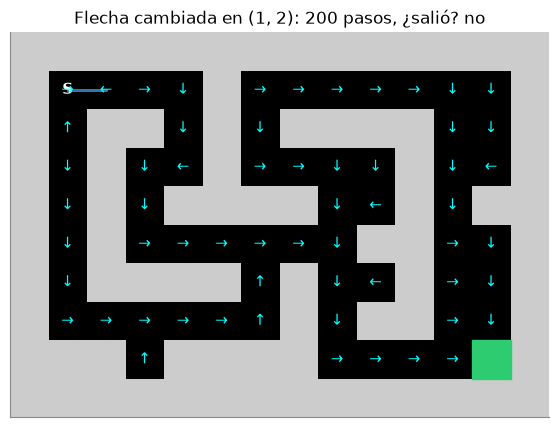

In [9]:
# TODO: cambiar la casilla (fila, columna) y la flecha, y volver a ejecutar
casilla = (1, 2)
nueva_flecha = IZQUIERDA

mi_politica = politica_flechas.copy()
mi_politica[env.pos2s[casilla]] = nueva_flecha
camino_ej, _, llego_ej = correr_episodio(env, np.random.default_rng(SEMILLA), mi_politica)
env.plot(policy=mi_politica, path=camino_ej,
         title=f"Flecha cambiada en {casilla}: {len(camino_ej) - 1} pasos, ¿salió? {'sí' if llego_ej else 'no'}")
plt.show()

## 4. Qué se maximiza: un agente aleatorio en la cueva

El objetivo del agente no es la recompensa de *este* paso sino la suma de todas las que vienen:

$$\text{maximizar}\quad \mathbb{E}\left[\, r_1 + r_2 + r_3 + \dots \right]$$

En la cueva esa suma vale 1 si sale y 0 si no. Volvamos al agente más tonto posible, el que elige **al azar**, y miremos qué recibe.

### Paso 1 — Un episodio a ciegas

El mismo episodio de tres maneras: lo que ve el agente (nada), lo que descubrió (las paredes que tocó, en gris claro, como en el juego) y el mapa real. El juego se corta a los 200 pasos.

Pasos: 200  |  ¿llegó a la salida? False  |  recompensa total: 0.0


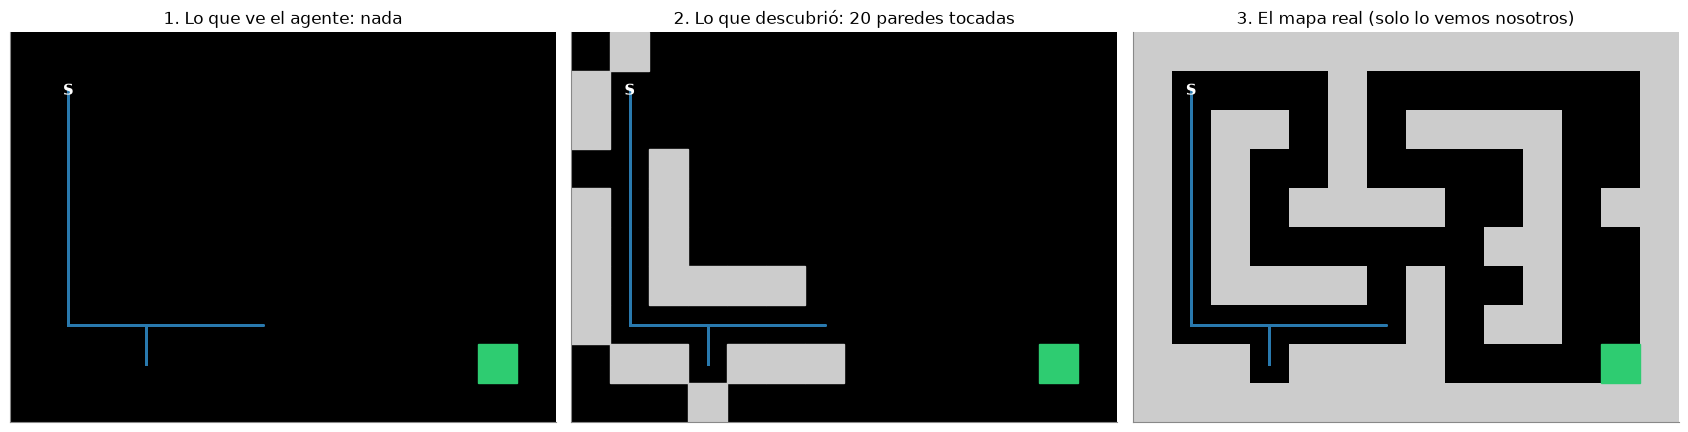

In [10]:
rng = np.random.default_rng(SEMILLA)
camino, retorno, llego = correr_episodio(env, rng)
print(f"Pasos: {len(camino) - 1}  |  ¿llegó a la salida? {llego}  |  recompensa total: {retorno}")
tres_vistas(env, camino)

En 200 pasos no llega. Recompensa total: **0**. Notar que el agente *no recibió ninguna pista* de que iba mal: con recompensa 0 en cada paso, perderse y acercarse se ven igual.

### Paso 2 — Una partida real, número por número

Ahora dejamos jugar al azar sin límite hasta que salga, y anotamos la recompensa de cada paso. Abajo, para comparar, la partida de las flechas fijas.

Al azar:    0 0 0 0 0 0 0 0 0 0 0 0 ... 0 0 1
            1833 ceros y un +1 en el paso 1834  →  suma = 1
Flechas:    19 ceros y un +1 en el paso 20  →  suma = 1


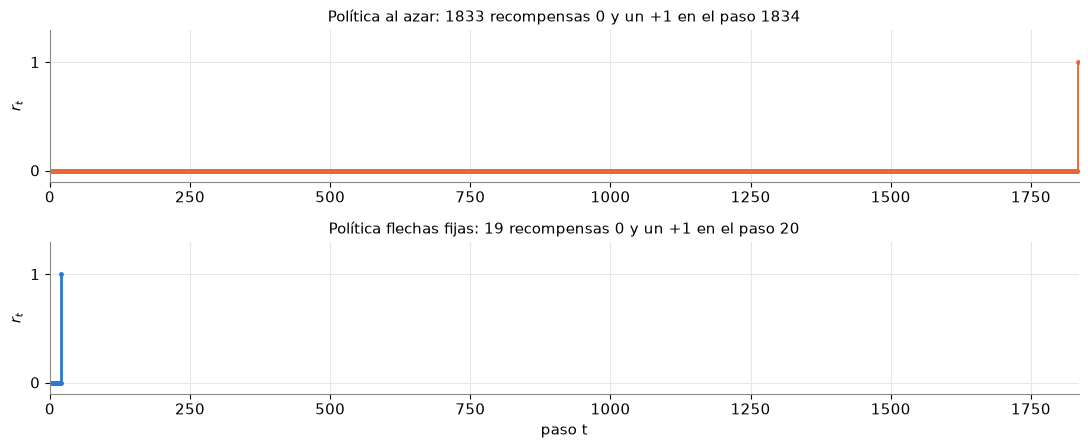

In [11]:
env_sin_limite = CaveEnv(max_steps=10**6)
rs_azar, _ = recompensas_de_un_episodio(env_sin_limite, np.random.default_rng(SEMILLA))
rs_flechas, _ = recompensas_de_un_episodio(env_sin_limite, np.random.default_rng(SEMILLA), politica_flechas)
print("Al azar:   ", " ".join(f"{r:.0f}" for r in rs_azar[:12]), "...", " ".join(f"{r:.0f}" for r in rs_azar[-3:]))
print(f"            {int(np.sum(rs_azar == 0))} ceros y un +1 en el paso {len(rs_azar)}  →  suma = {rs_azar.sum():.0f}")
print(f"Flechas:    {int(np.sum(rs_flechas == 0))} ceros y un +1 en el paso {len(rs_flechas)}  →  suma = {rs_flechas.sum():.0f}")
dibujar_recompensas(rs_azar, rs_flechas)

Las dos partidas suman exactamente lo mismo: **1**. La suma de recompensas no distingue una salida rápida de una lentísima (eso lo arregla el descuento de la clase 3). Y en la partida del azar, ¿cuál de todos esos pasos fue el bueno? Ningún número lo dice: el +1 llega al final y hay que repartir el mérito entre todo lo anterior. A esto se le llama **recompensa escasa** (*sparse reward*) y **demorada**; es el tema de la clase 7.

### Paso 3 — Muchos episodios: ¿cuánto tarda el azar en salir?

Los mismos 300 episodios al azar de la sección 3, ahora como histograma.

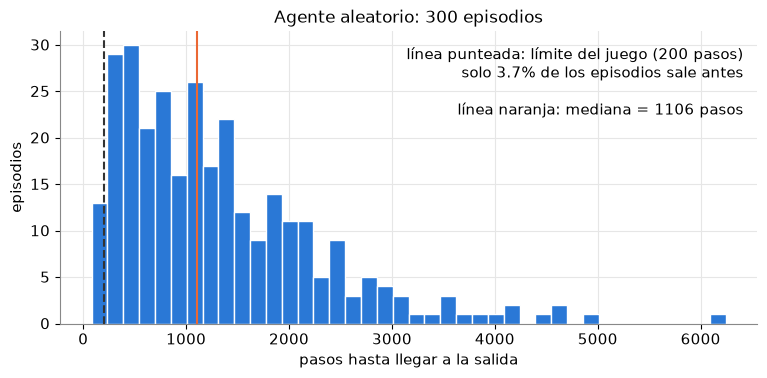

In [12]:
exito = histograma_pasos(pasos_azar, limite=200)

Con 200 pasos, el azar sale en muy pocos episodios y la mediana está muy por encima del límite, aunque las flechas muestran que la salida está a pocos pasos. Ese porcentaje es lo que un algoritmo de RL tiene que mejorar **usando solo la recompensa**: casi nunca ve un +1 del cual aprender.

### ✍️ Ejercicio

Cambien el límite de pasos (`limite`) a 500 o 1000 y miren cómo cambia el % de éxito. Cambien también `SEMILLA_EJ` para ver otro episodio a ciegas: ¿cuántas paredes llega a tocar?

Con 200 pasos, el azar sale en el 3.7% de los episodios


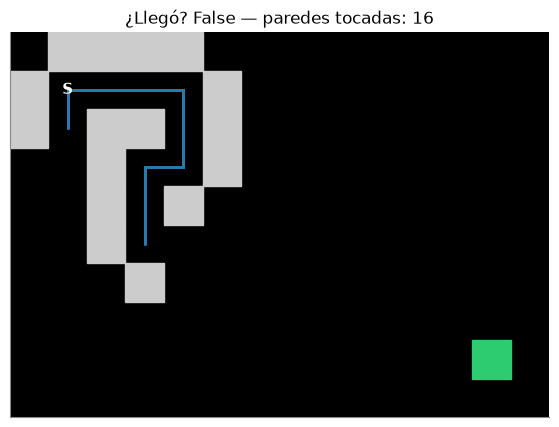

In [13]:
# TODO: cambiar estos valores y volver a ejecutar
limite = 200
SEMILLA_EJ = 1

print(f"Con {limite} pasos, el azar sale en el {np.mean(pasos_azar <= limite) * 100:.1f}% de los episodios")
env_ej = CaveEnv(max_steps=limite)
camino_ej, _, llego_ej = correr_episodio(env_ej, np.random.default_rng(SEMILLA_EJ))
pintar_paredes_tocadas(env_ej, camino_ej, title=f"¿Llegó? {llego_ej} — paredes tocadas: {len(env_ej.touched)}")
plt.show()

## 5. Historia vs. estado: ¿qué tiene que recordar el agente?

Todo lo que el agente vivió hasta ahora es su **historia** (*history*):

$$h_t = (a_1, o_1, r_1,\; a_2, o_2, r_2,\; \dots,\; a_t, o_t, r_t)$$

La historia crece en cada paso. Guardarla entera es caro: queremos un resumen, el **estado** (*state*) $s_t = f(h_t)$, que alcance para decidir. La política de la sección 3 usaba como estado la casilla. ¿Alcanza?

### Paso 1 — Dos historias, una misma casilla

Dos recorridos distintos desde `S` que terminan en la misma casilla. Pregunta: ¿el futuro depende de *cómo* llegó?

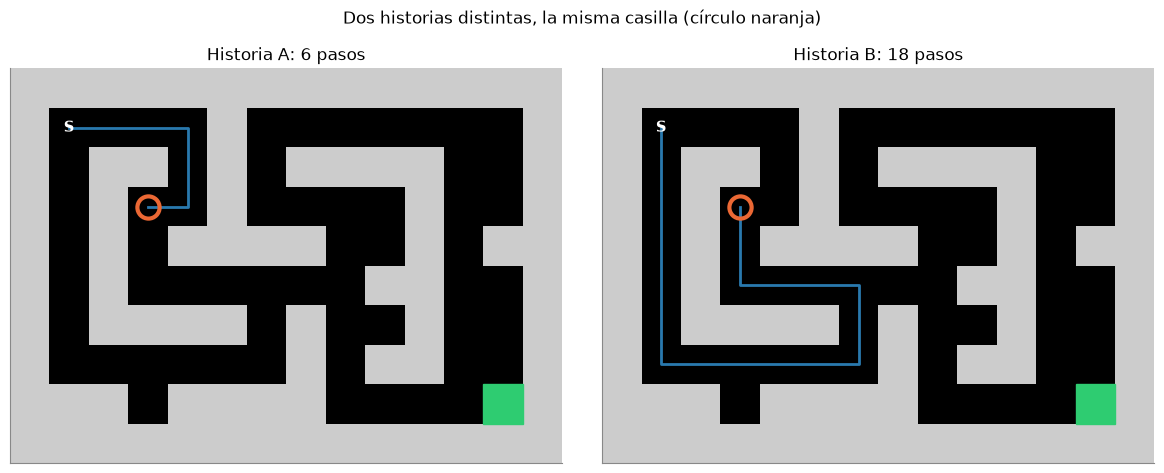

¿Terminan en el mismo estado? True
Flecha de la política en esa casilla: ↓


In [14]:
historia_A = [DERECHA] * 3 + [ABAJO] * 2 + [IZQUIERDA]
historia_B = [ABAJO] * 6 + [DERECHA] * 5 + [ARRIBA] * 2 + [IZQUIERDA] * 3 + [ARRIBA] * 2

fin_A, fin_B = dos_historias(env, historia_A, historia_B)
print("¿Terminan en el mismo estado?", fin_A == fin_B)
print("Flecha de la política en esa casilla:", ACTION_NAMES[politica_flechas[fin_A]])

No importa el camino: en la cueva, lo que pase después depende solo de **dónde estoy** y **qué hago ahora**. Por eso la política de flechas puede tener una sola flecha por casilla. La **posición alcanza** como estado. Eso es el **supuesto de Markov** (*Markov assumption*):

$$p(s_{t+1} \mid s_t, a_t) = p(s_{t+1} \mid h_t, a_t)$$

"El futuro es independiente del pasado, dado el presente."

### Adelanto de la clase 9 — ¿Y si el agente solo sintiera paredes?

Supongamos que el agente no sabe su posición y solo tiene cuatro "bigotes" que le dicen si hay pared arriba, a la derecha, abajo o a la izquierda. Contemos cuántas sensaciones distintas hay.

In [15]:
firmas = [firma_paredes(env, s) for s in range(env.nS)]
print(f"Hay {env.nS} casillas pero solo {len(set(firmas))} sensaciones distintas.")

Hay 60 casillas pero solo 12 sensaciones distintas.


Muchas casillas se sienten igual y en algunas conviene ir a un lado y en otras al otro: con solo los bigotes, **la observación no es Markov** y el agente necesita recordar parte de la historia. Ese es el tema de la clase 9 (redes recurrentes: cuando el estado no alcanza).

| El agente percibe… | ¿Es Markov? |
|---|---|
| su posición (casilla) | **sí**: la posición alcanza |
| solo las 4 paredes vecinas | **no**: necesita memoria |

## 6. Aula invertida: el tutor de IA como proceso de decisión

*(Ejercicio de Emma Brunskill, CS234, clase 1.)* Ahora **ustedes** son quienes diseñan el problema.

> Un alumno **no sabe sumar** (fácil de aprender) **ni restar** (difícil). Un tutor de IA le va dando problemas: en cada turno elige **un problema de suma o uno de resta**. El tutor recibe **+1 si el alumno responde bien y −1 si responde mal**.

**En grupos, 5 minutos, antes de seguir leyendo:**

1. ¿Quién es el **agente** y quién el **entorno**? ¿Cuál es el **estado**, la **acción** y la **recompensa**?
2. ¿Qué representa la **dinámica** (cómo cambia el estado)?
3. Si el tutor maximiza la recompensa esperada, **¿qué política va a aprender?**

<br>

---

### Para discutir después

- **Agente**: el tutor. **Entorno**: el alumno.
- **Acción**: dar un problema de suma o de resta.
- **Estado**: lo que el tutor sabe del alumno (por ejemplo, su historial de aciertos y errores, o un nivel estimado en suma y en resta).
- **Recompensa**: +1 / −1 según acierte.
- **Dinámica**: cómo cambia el nivel del alumno al practicar.
- **Política**: la regla con la que el tutor elige el próximo problema.
- **La respuesta incómoda**: la política óptima es **dar solo sumas**. Las sumas se aprenden rápido, se aciertan, y suman puntos. Las restas cuestan y restan puntos. El tutor "gana" sin enseñar a restar. Esto se llama **trampa de la recompensa** (*reward hacking*): el agente optimiza exactamente lo que le pedimos, no lo que queríamos (Amodei et al., 2016).

### Paso 1 — Simulemos al alumno

Un modelo mínimo: el alumno acierta con una probabilidad (su "habilidad"). Cada vez que practica un tipo de problema, esa habilidad sube: rápido en suma, lento en resta. Comparamos tres políticas fijas del tutor durante 60 problemas, promediando 300 alumnos simulados.

Habilidad inicial: {'suma': 0.1, 'resta': 0.05} | velocidad de aprendizaje: {'suma': 0.12, 'resta': 0.04}


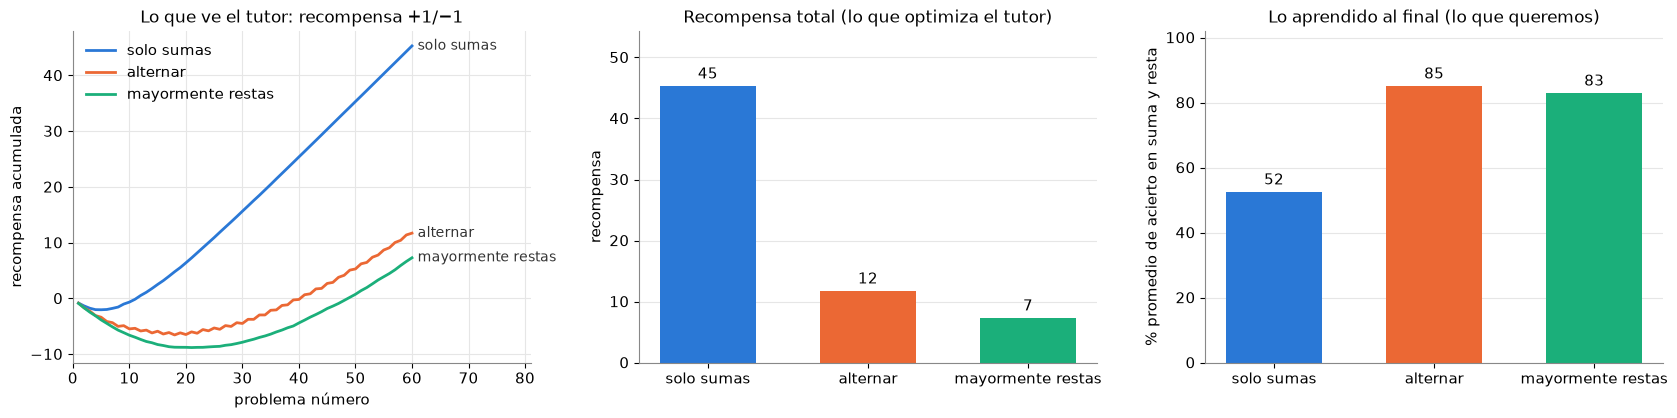

política              recompensa  suma final  resta final
solo sumas                  45.3        100%           5%
alternar                    11.7         98%          72%
mayormente restas            7.3         79%          86%


In [16]:
print("Habilidad inicial:", HAB_INICIAL, "| velocidad de aprendizaje:", VELOCIDAD)
comparar_politicas_tutor()

**El desalineamiento, en una figura**: el gráfico del medio y el de la derecha ordenan las políticas al revés.

- "Solo sumas" gana en recompensa… y deja al alumno sin saber restar.
- "Alternar" y "mayormente restas" suman muchos menos puntos (al principio el alumno se equivoca mucho y la recompensa acumulada baja), pero al final el alumno sabe las dos cosas.

Un algoritmo de RL bien hecho, con esta recompensa, *encontraría* "solo sumas". El problema no está en el algoritmo sino en **cómo definimos la recompensa**. Diseñar la recompensa es parte del trabajo (y en muchos problemas reales, la parte más difícil).

## ✍️ Ejercicio — Ustedes son el docente: rediseñen la recompensa

La función `mi_recompensa` recibe si el alumno acertó, el tipo de problema y su habilidad **antes** y **después** de practicar (diccionarios con `"suma"` y `"resta"`). Ahora devuelve lo mismo que la original (+1/−1).

Cámbienla para que **la política que más recompensa obtiene sea también la que más enseña**. Ideas para probar (una por vez):

- premiar más los aciertos en resta que en suma;
- no castigar los errores;
- premiar la **mejora**: `hab_despues[tipo] - hab_antes[tipo]`.

Después discutan: ¿esa información la tendría un tutor real? ¿Cómo podría el tutor **engañar** a la recompensa nueva? (En la clase 4 escribimos el tutor como MDP; en la 12 vemos cómo aprender la recompensa a partir de preferencias de personas, como en RLHF.)

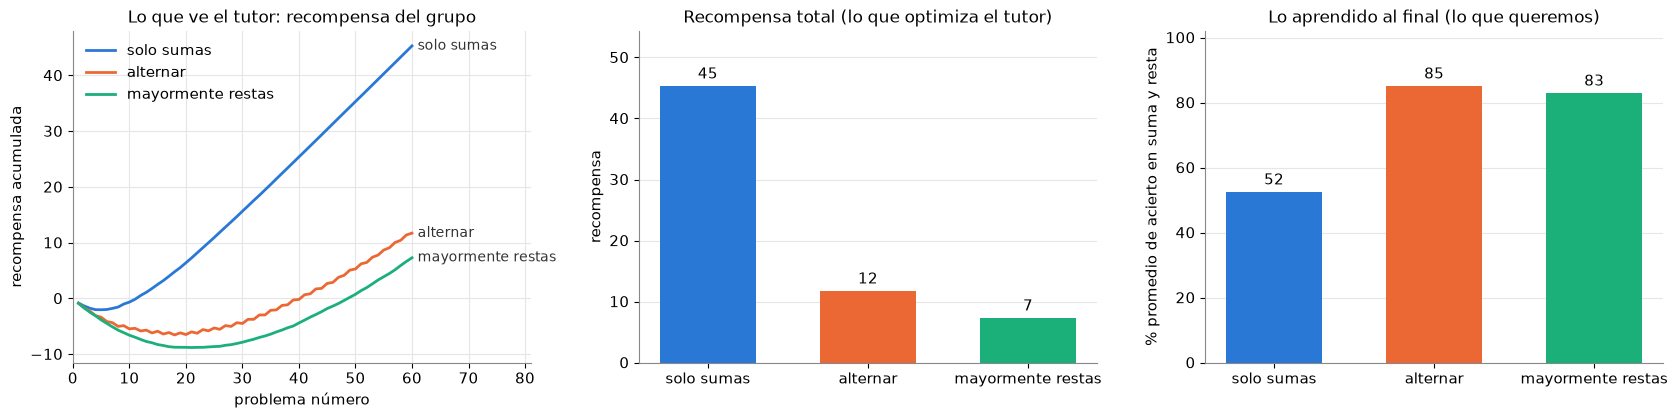

política              recompensa  suma final  resta final
solo sumas                  45.3        100%           5%
alternar                    11.7         98%          72%
mayormente restas            7.3         79%          86%


In [17]:
def mi_recompensa(acierto, tipo, hab_antes, hab_despues):
    # TODO: cambiar esta línea por la recompensa que diseñe el grupo
    return 1.0 if acierto else -1.0

comparar_politicas_tutor(recompensa=mi_recompensa, titulo_r="recompensa del grupo")

## Preguntas para pensar

1. En la cueva, la recompensa es +1 solo al salir. Si en cambio diéramos −0.01 por cada paso, ¿qué cambiaría en lo que el agente "quiere"? ¿Podría aparecer otra trampa de la recompensa?
2. Elijan otro problema (un videojuego, un termostato, un recomendador de videos): ¿cuál es el agente, el entorno, la acción, la observación, la recompensa y la política? ¿Su observación cumple el supuesto de Markov?
3. En el tutor, el nivel real del alumno no se observa: solo sus aciertos. ¿Cómo estimarían el estado a partir de la historia?

## Próxima clase

La casilla alcanza para decidir: el futuro depende solo del presente. En la clase 3 armamos con eso la **cadena de Markov** de la cueva y le damos un número a **cuánto pesa el futuro** (el descuento $\gamma$), parecido a una tasa de interés que hace valer menos una recompensa lejana.